# Overview of Logistic Regression & Sigmoid Function

Logistic Regression adalah metode statistik fundamental yang digunakan untuk masalah klasifikasi biner. Berbeda dengan regresi linier yang memprediksi luaran kontinu, regresi logistik memprediksi probabilitas $P(Y=1\vert{}X)$ bahwa masukan tertentu milik kelas positif. Hal ini dicapai dengan menerapkan fungsi sigmoid (fungsi logistik) pada kombinasi linier fitur:

$$P(Y=1\vert{}\mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}, \quad \text{dimana } z = \beta_0 + \beta_1 x_1 + \dots + \beta_n x_n = \mathbf{x}^T \boldsymbol{\beta}$$

Aturan keputusannya sederhana: jika $P(Y=1\vert{}\mathbf{x}) \ge 0.5$ (atau $z \ge 0$), prediksi Kelas 1; jika tidak, prediksi Kelas 0. Parameter model diestimasi menggunakan Maximum Likelihood Estimation (MLE) yang meminimalkan binary cross-entropy loss:

$$\text{Loss}_{\text{BCE}}(\boldsymbol{\beta}) = -\frac{1}{N} \sum_{i=1}^{N} \left[ y_i \log(\hat{y}_i) + (1 - y_i) \log(1 - \hat{y}_i) \right]$$

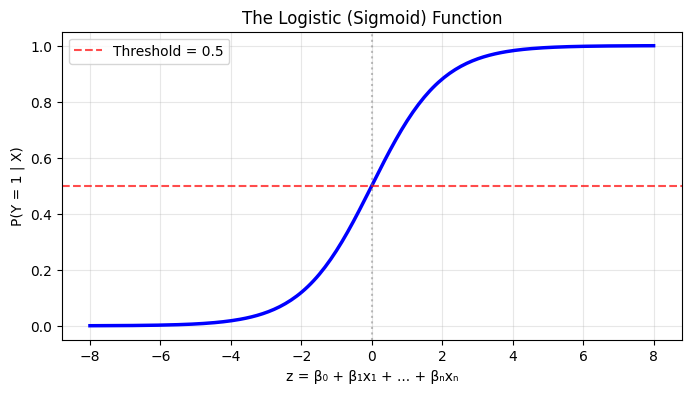

Dataset Shape: 569 sampel, 30 fitur
Akurasi Regresi Logistik Dasar: 0.9474

              precision    recall  f1-score   support

   Malignant       0.92      0.96      0.94        46
      Benign       0.97      0.94      0.96        68

    accuracy                           0.95       114
   macro avg       0.94      0.95      0.95       114
weighted avg       0.95      0.95      0.95       114



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

np.random.seed(2024)
warnings.filterwarnings('ignore')

# 1. Visualisasi Fungsi Sigmoid
z = np.linspace(-8, 8, 200)
sigmoid = 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(z, sigmoid, 'b-', linewidth=2.5)
ax.axhline(y=0.5, color='red', linestyle='--', alpha=0.7, label='Threshold = 0.5')
ax.axvline(x=0, color='gray', linestyle=':', alpha=0.5)
ax.set_xlabel('z = β₀ + β₁x₁ + ... + βₙxₙ')
ax.set_ylabel('P(Y = 1 | X)')
ax.set_title('The Logistic (Sigmoid) Function')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
plt.show()

# 2. Memuat dan Membagi Dataset Breast Cancer Wisconsin
data = load_breast_cancer()
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2024
)

# 3. Fit Model Regresi Logistik Standar
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
acc_base = accuracy_score(y_test, y_pred)

print(f"Dataset Shape: {X.shape[0]} sampel, {X.shape[1]} fitur")
print(f"Akurasi Regresi Logistik Dasar: {acc_base:.4f}\n")
print(classification_report(y_test, y_pred, target_names=['Malignant', 'Benign']))

- Fungsi Sigmoid: Mengubah sembarang masukan bernilai riil $z$ menjadi rentang probabilitas $[0, 1]$. Nilai $z=0$ menghasilkan probabilitas tepat $0.5$.

- Dataset Breast Cancer: Terdiri dari $569$ sampel dengan $30$ fitur. Model dasar Regresi Logistik langsung menghasilkan akurasi $95\%$ ($108$ benar dari $114$ data uji).

- Laporan Klasifikasi: Presisi dan recall seimbang pada kelas Malignant (Ganas) dan Benign (Jinak).

# Multiclass Classification Techniques (OvR vs. Multinomial)

Regresi logistik diperluas ke banyak kelas ($K > 2$) menggunakan dua pendekatan:

1. One-vs-Rest (OvR): Melatih $K$ classifier biner terpisah. Setiap classifier $k$ membedakan kelas $k$ melawan gabungan seluruh kelas lainnya. Klasifikasi akhir memilih kelas dengan skor probabilitas tertinggi.  

2. Multinomial (Softmax) Regression: Memodelkan probabilitas seluruh kelas secara bersamaan menggunakan fungsi Softmax:
$$P(Y = k \vert{} \mathbf{x}) = \frac{e^{\mathbf{x}^T \boldsymbol{\beta}_k}}{\sum_{j=1}^{K} e^{\mathbf{x}^T \boldsymbol{\beta}_j}}$$

Fungsi Softmax menjamin total probabilitas seluruh kelas sama dengan $1.0$.

In [ ]:
from sklearn.datasets import load_iris
from sklearn.multiclass import OneVsRestClassifier

# Memuat dataset Iris (3 kelas)
iris = load_iris()
X_ir, y_ir = iris.data, iris.target

X_tr_ir, X_te_ir, y_tr_ir, y_te_ir = train_test_split(
    X_ir, y_ir, test_size=0.3, random_state=2024
)

# A. Approach 1: One-vs-Rest (OvR)
ovr_model = OneVsRestClassifier(LogisticRegression(solver='liblinear', max_iter=1000))
ovr_model.fit(X_tr_ir, y_tr_ir)
y_pred_ovr = ovr_model.predict(X_te_ir)

# B. Approach 2: Multinomial (Softmax)
multi_model = LogisticRegression(solver='lbfgs', max_iter=1000)
multi_model.fit(X_tr_ir, y_tr_ir)
y_pred_multi = multi_model.predict(X_te_ir)

print(f"Akurasi OvR         : {accuracy_score(y_te_ir, y_pred_ovr):.4f}")
print(f"Akurasi Multinomial : {accuracy_score(y_te_ir, y_pred_multi):.4f}")

Akurasi OvR         : 0.9556
Akurasi Multinomial : 0.9333


- OneVsRestClassifier: Membungkus estimator logistik biner untuk menjalankan strategi OvR secara eksplisit.

- Perbandingan Performa: OvR mencapai akurasi $95.56\%$ sedangkan Multinomial mencapai $93.33\%$ pada dataset Iris. Kedua model mengklasifikasikan spesies Setosa secara sempurna ($100\%$), dan kesalahan fokus pada perbatasan kelas Versicolor dan Virginica.

# Regularization in Logistic Regression ($L_1$ vs. $L_2$)

Regulerisasi pada regresi logistik menambahkan penalti pada cross-entropy loss untuk mencegah overfitting:
- Ridge ($L_2$): Menambahkan penalti kuadrat norma koefisien ($\frac{1}{2C} \Vert{}\boldsymbol{\beta}\Vert{}_2^2$).   

- Lasso ($L_1$): Menambahkan penalti nilai mutlak norma koefisien ($\frac{1}{C} \Vert{}\boldsymbol{\beta}\Vert{}_1$)

Konvensi $C$ pada scikit-learn: Berbeda dengan regresi linier yang menggunakan $\alpha$, LogisticRegression menggunakan parameter $C = \frac{1}{\alpha}$. Nilai $C$ yang semakin kecil menandakan regulerisasi yang semakin kuat. Skalasi data (StandardScaler) wajib dilakukan sebelum regulerisasi.   

In [ ]:
from sklearn.preprocessing import StandardScaler

# Membagi dataset Breast Cancer (70/30) dan melakukan Scaling
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    data.data, data.target, test_size=0.3, random_state=2024
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_reg)
X_test_scaled = scaler.transform(X_test_reg)

# 1. Ridge Logistic Regression (L2 penalty, C=0.1)
ridge_log = LogisticRegression(penalty='l2', solver='liblinear', C=0.1)
ridge_log.fit(X_train_scaled, y_train_reg)
y_pred_ridge = ridge_log.predict(X_test_scaled)

# 2. Lasso Logistic Regression (L1 penalty, C=0.1)
lasso_log = LogisticRegression(penalty='l1', solver='liblinear', C=0.1)
lasso_log.fit(X_train_scaled, y_train_reg)
y_pred_lasso = lasso_log.predict(X_test_scaled)

print("Ridge (L2, C=0.1) -> Akurasi:", f"{accuracy_score(y_test_reg, y_pred_ridge):.4f}",
      f"| Fitur Aktif: {np.sum(ridge_log.coef_[0] != 0)}/30")
print("Lasso (L1, C=0.1) -> Akurasi:", f"{accuracy_score(y_test_reg, y_pred_lasso):.4f}",
      f"| Fitur Aktif: {np.sum(lasso_log.coef_[0] != 0)}/30")

Ridge (L2, C=0.1) -> Akurasi: 0.9825 | Fitur Aktif: 30/30
Lasso (L1, C=0.1) -> Akurasi: 0.9649 | Fitur Aktif: 7/30


- Ridge ($L_2$, $C=0.1$): Menghasilkan akurasi tinggi ($98.25\%$) dengan mempertahankan seluruh $30$ fitur (mengecilkan koefisien secara seragam tanpa menghapusnya).

- Lasso ($L_1$, $C=0.1$): Mencapai akurasi 96.49% hanya dengan menggunakan 7 dari 30 fitur (memangkas 23 fitur berlebih hingga bernilai nol tepat). Ini mempermudah interpretasi klinis dan menghemat biaya pengumpulan data.

# Multilabel Classification Concepts

Dalam Multilabel Classification, setiap sampel data dapat memiliki beberapa label target sekaligus (misal: satu artikel berita memiliki topik "Politik" dan "Ekonomi"). Pendekatan paling sederhana adalah Binary Relevance, yaitu melatih satu binary classifier independen untuk setiap label target.

In [ ]:
from sklearn.datasets import make_multilabel_classification

# Generate dataset multilabel sintetis
X_ml, y_ml = make_multilabel_classification(
    n_samples=1000, n_features=20, n_classes=5, n_labels=2, random_state=2024
)

X_tr_ml, X_te_ml, y_tr_ml, y_te_ml = train_test_split(
    X_ml, y_ml, test_size=0.3, random_state=2024
)

# Melatih 1 Logistic Regression untuk setiap label (Binary Relevance)
y_pred_ml_list = []
for i in range(y_tr_ml.shape[1]):
    m = LogisticRegression(solver='liblinear')
    m.fit(X_tr_ml, y_tr_ml[:, i])
    y_pred_ml_list.append(m.predict(X_te_ml))

y_pred_ml = np.array(y_pred_ml_list).T

# Evaluasi Exact Match Accuracy
exact_match = accuracy_score(y_te_ml, y_pred_ml)
print(f"Dataset Multilabel: {X_ml.shape[0]} sampel, {y_ml.shape[1]} label")
print(f"Exact Match Accuracy: {exact_match:.4f}")

Dataset Multilabel: 1000 sampel, 5 label
Exact Match Accuracy: 0.3400


- make_multilabel_classification: Membuat dataset dengan $5$ label target simultan.

- Exact Match Accuracy: Mencapai $34.00\%$. Metrik ini sangat ketat karena mewajibkan seluruh $5$ label diprediksi benar secara bersamaan pada suatu sampel. Performa per-label bervariasi tergantung pada frekuensi kemunculan label (label imbalance).

# Model Evaluation Metrics & ROC-AUC Curve

Evaluasi klasifikasi tidak hanya bertumpu pada Akurasi, melainkan juga:
- Precision: Proporsi prediksi positif yang benar-benar positif ($\frac{TP}{TP + FP}$).

- Recall (Sensitivity): Proporsi kasus positif asli yang berhasil terdeteksi ($\frac{TP}{TP + FN}$).

- F1-Score: Rata-rata harmonis antara Precision dan Recall ($2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$).

- ROC-AUC: Luas area di bawah kurva Receiver Operating Characteristic yang mengukur kemampuan model dalam membedakan antar-kelas di seluruh ambang batas (threshold) probabilitas $[0, 1]$.

Precision : 0.94
Recall    : 0.95
F1-Score  : 0.95
ROC-AUC   : 0.99


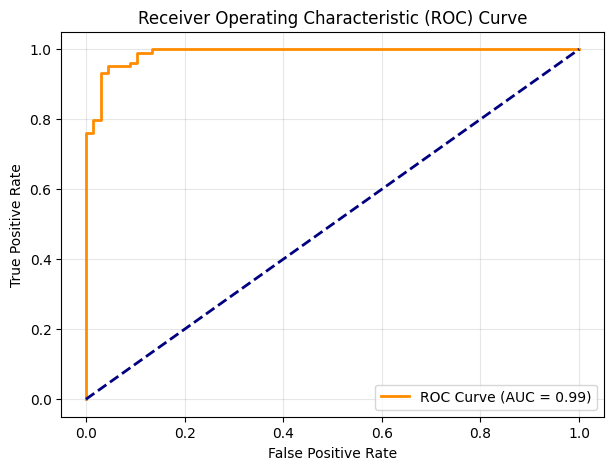

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_curve, auc

# Evaluasi model Breast Cancer
model_eval = LogisticRegression(solver='liblinear')
model_eval.fit(X_train_reg, y_train_reg)

y_pred_eval = model_eval.predict(X_test_reg)
y_prob_eval = model_eval.predict_proba(X_test_reg)[:, 1]

# Menghitung Metrik Evaluasi
precision = precision_score(y_test_reg, y_pred_eval)
recall = recall_score(y_test_reg, y_pred_eval)
f1 = f1_score(y_test_reg, y_pred_eval)
fpr, tpr, _ = roc_curve(y_test_reg, y_prob_eval)
roc_auc = auc(fpr, tpr)

print(f"Precision : {precision:.2f}")
print(f"Recall    : {recall:.2f}")
print(f"F1-Score  : {f1:.2f}")
print(f"ROC-AUC   : {roc_auc:.2f}")

# Plot Kurva ROC
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

- Skor ROC-AUC (0.99): Menunjkukkan kemampuan pemisahan (discrimination power) model yang sangat mendekatu sempurna.

- Interpretasi Klinis: Kurva ROC yang mendekati sudut kiri atas menunjukan bahwa model dapat mencapai True Positivie Rate (Recall) $\approx 95\%$ dengan menekan False Positive Rate tetap sangat rendah ($< 5\%$).